<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/uniface_exploracion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧑‍🦱 Explorando UniFace paso a paso
Librería de análisis facial todo-en-uno: **detección, alineación, reconocimiento, atributos, landmarks, face mesh, parsing, matting, mirada, pose de cabeza, anti-spoofing, calidad, anonimización, tracking y vector store**.
Repositorio: https://github.com/yakhyo/uniface · Docs: https://yakhyo.github.io/uniface
> Funciona en CPU (ONNX Runtime). Para GPU instala `uniface[gpu]`. Los pesos se descargan solos la primera vez.
> ⚠️ La API cambia entre versiones mayores. Las celdas con ⚙️ están protegidas con `safe()`: si una falla, el resto sigue y te indica qué revisar en la documentación.

## 0. Instalación

In [1]:
!pip -q install "uniface[cpu]" faiss-cpu
!git clone -q --depth 1 https://github.com/yakhyo/uniface.git uniface_repo
import importlib.metadata as md
print("uniface", md.version("uniface"))

uniface 4.2.1


In [2]:
import os, glob, time, inspect, pkgutil, importlib, traceback
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import uniface

def show(images, titles=None, size=5):
    fig, ax = plt.subplots(1, len(images), figsize=(size*len(images), size*0.9))
    ax = np.atleast_1d(ax)
    for i, im in enumerate(images):
        ax[i].imshow(im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax[i].axis("off")
        if titles: ax[i].set_title(titles[i], fontsize=11)
    plt.tight_layout(); plt.show()

def safe(label, fn, hint="https://yakhyo.github.io/uniface/"):
    """Ejecuta una demo; si la API cambió, avisa sin romper el notebook."""
    try: return fn()
    except Exception as e:
        print(f"⚠️ {label}: {type(e).__name__}: {e}\n   Revisa la API en {hint}"); return None

_mods = {}
def find(name):
    """Busca una clase/función de UniFace en el paquete y en todos sus submódulos."""
    if not _mods:
        _mods["uniface"] = uniface
        for p in pkgutil.iter_modules(uniface.__path__):
            try: _mods[p.name] = importlib.import_module(f"uniface.{p.name}")
            except Exception: pass
    for m in _mods.values():
        if hasattr(m, name): return getattr(m, name)
    raise ImportError(f"'{name}' no existe en esta versión de uniface")

def crop(img, bbox, m=0.25):
    x1, y1, x2, y2 = [int(v) for v in bbox[:4]]
    w, h = x2-x1, y2-y1
    x1, y1 = max(0, int(x1-w*m)), max(0, int(y1-h*m)); x2, y2 = min(img.shape[1], int(x2+w*m)), min(img.shape[0], int(y2+h*m))
    return img[y1:y2, x1:x2]

def draw(img, faces, label=lambda f: ""):
    out = img.copy()
    for f in faces:
        x1, y1, x2, y2 = [int(v) for v in f.bbox[:4]]
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 2)
        if getattr(f, "landmarks", None) is not None:
            for (px, py) in np.array(f.landmarks).reshape(-1, 2): cv2.circle(out, (int(px), int(py)), 3, (0, 0, 255), -1)
        t = label(f)
        if t: cv2.putText(out, t, (x1, max(y1-8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    return out

## 1. Mapa de la API: ¿qué trae el repositorio?

In [62]:
find("RetinaFace")   # fuerza la carga de submódulos
rows = []
for name, m in sorted(_mods.items()):
    cls = [n for n,
           o in inspect.getmembers(m,
                                   inspect.isclass) if o.__module__.startswith("uniface") and not n.startswith("_")]
    if cls: rows.append([name, len(cls), ", ".join(cls[:8]) + ("..." if len(cls) > 8 else "")])
pd.DataFrame(rows, columns=["módulo", "clases", "ejemplos"])

,módulo,clases,ejemplos
0,analyzer,9,"BaseAttribute, BaseDetector, BaseRecognizer, E..."
1,attribute,9,"AgeGender, BaseAttribute, DemographyResult, Em..."
2,constants,26,"AdaFaceWeights, AgeGenderWeights, ArcFaceWeigh..."
3,detection,7,"BaseDetector, BlazeFace, CenterFace, RetinaFac..."
4,gaze,3,"BaseGazeEstimator, GazeResult, MobileGaze"
5,headpose,3,"BaseHeadPoseEstimator, HeadPose, HeadPoseResult"
6,landmark,4,"BaseLandmarker, FaceMesh, Landmark106, PIPNet"
7,matting,2,"BaseMatting, MODNet"
8,parsing,3,"BaseFaceParser, BiSeNet, XSeg"
9,privacy,2,"BlurFace, EllipticalBlur"


## 2. Imágenes de ejemplo

46 imágenes en el repositorio


Attempt 1/3: 100%|██████████| 11.9M/11.9M [00:00<00:00, 93.0MB/s]


['astronaut.png', 'parse_face.jpg', 'seg_face.jpg', 'spoof_live.jpg', 'matte_hair.jpg', 'emotion_contempt.jpg']


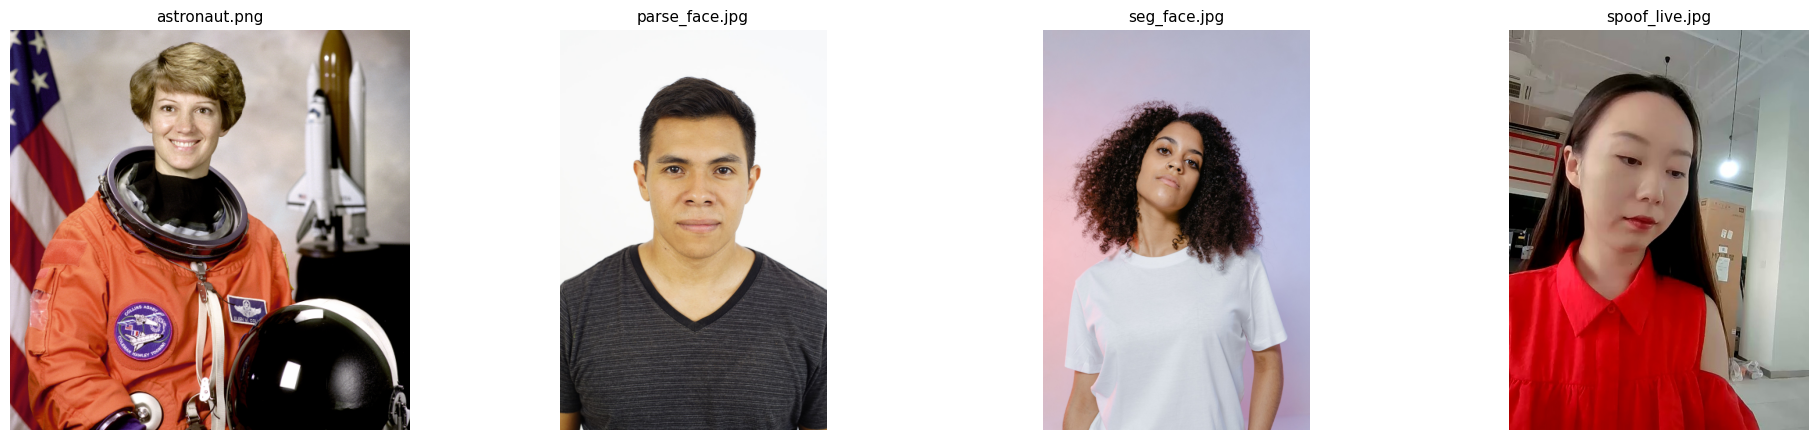

In [4]:
from skimage import data
cv2.imwrite("astronaut.png", cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR))
cands = [p for p in glob.glob("uniface_repo/assets/**/*", recursive=True)
         if p.lower().endswith((".jpg", ".jpeg", ".png")) and not any(k in p.lower() for k in ["demo", "logo", ".github"])]
print(len(cands), "imágenes en el repositorio")

RetinaFace = find("RetinaFace"); detector = RetinaFace()
IMGS = {}
for p in ["astronaut.png"] + cands:
    im = cv2.imread(p)
    if im is not None and len(detector.detect(im)) > 0: IMGS[os.path.basename(p)] = im
    if len(IMGS) >= 6: break
names = list(IMGS); print(names)
show([IMGS[n] for n in names[:4]], names[:4])

## 3. Detección de rostros + landmarks de 5 puntos

confianza=1.00
bbox=[180, 57, 270, 180]
landmarks=(5, 2)


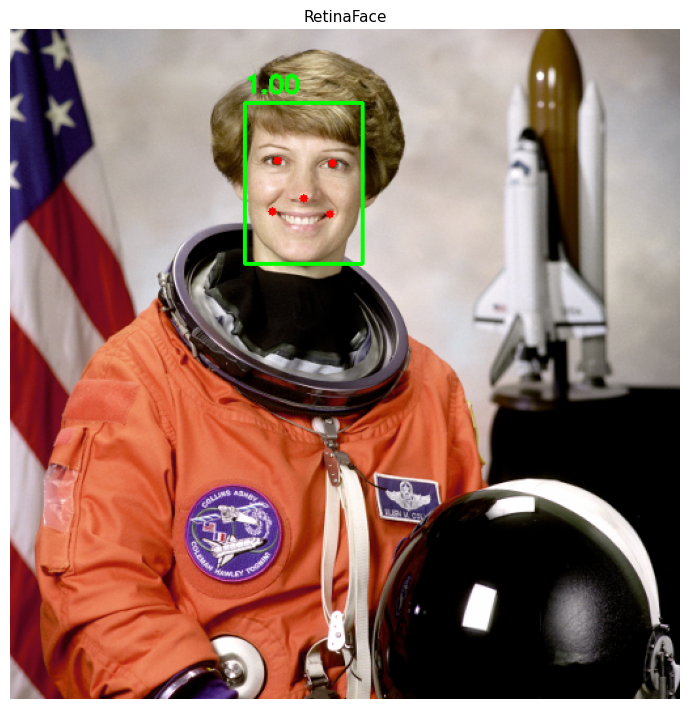

In [63]:
img = IMGS[names[0]]
faces = detector.detect(img)
for f in faces[:3]:
  print(f"confianza={f.confidence:.2f}")
  print(f"bbox={np.round(f.bbox).astype(int).tolist()}")
  print(f"landmarks={np.array(f.landmarks).shape}")
show([draw(img, faces, lambda f: f"{f.confidence:.2f}")], ["RetinaFace"], size=8)

confianza=1.00 · bbox=[121, 107, 297, 350] · landmarks=(5, 2)


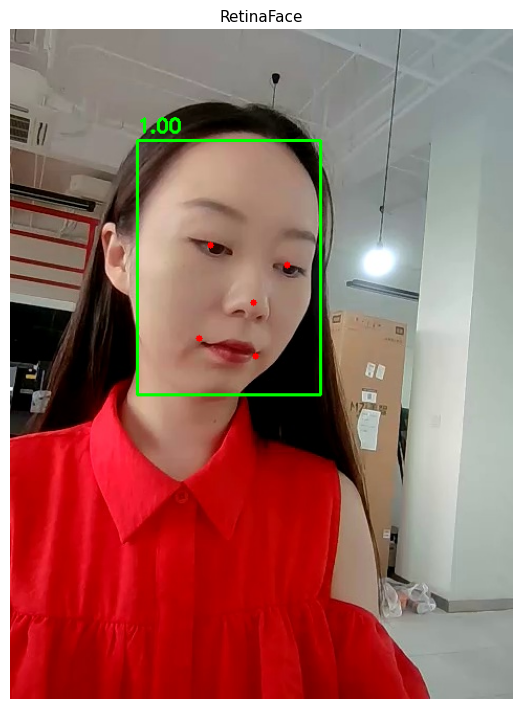

In [27]:
img = IMGS[names[3]]
faces = detector.detect(img)
for f in faces[:3]: print(f"confianza={f.confidence:.2f} · bbox={np.round(f.bbox).astype(int).tolist()} · landmarks={np.array(f.landmarks).shape}")
show([draw(img, faces, lambda f: f"{f.confidence:.2f}")], ["RetinaFace"], size=8)

### Comparar detectores

,detector,rostros,ms
0,RetinaFace,1,202.8
1,SCRFD,1,401.5
2,CenterFace,1,80.4
3,BlazeFace,1,3.1
4,YOLOv5Face,1,236.2
5,YOLOv8Face,1,140.8


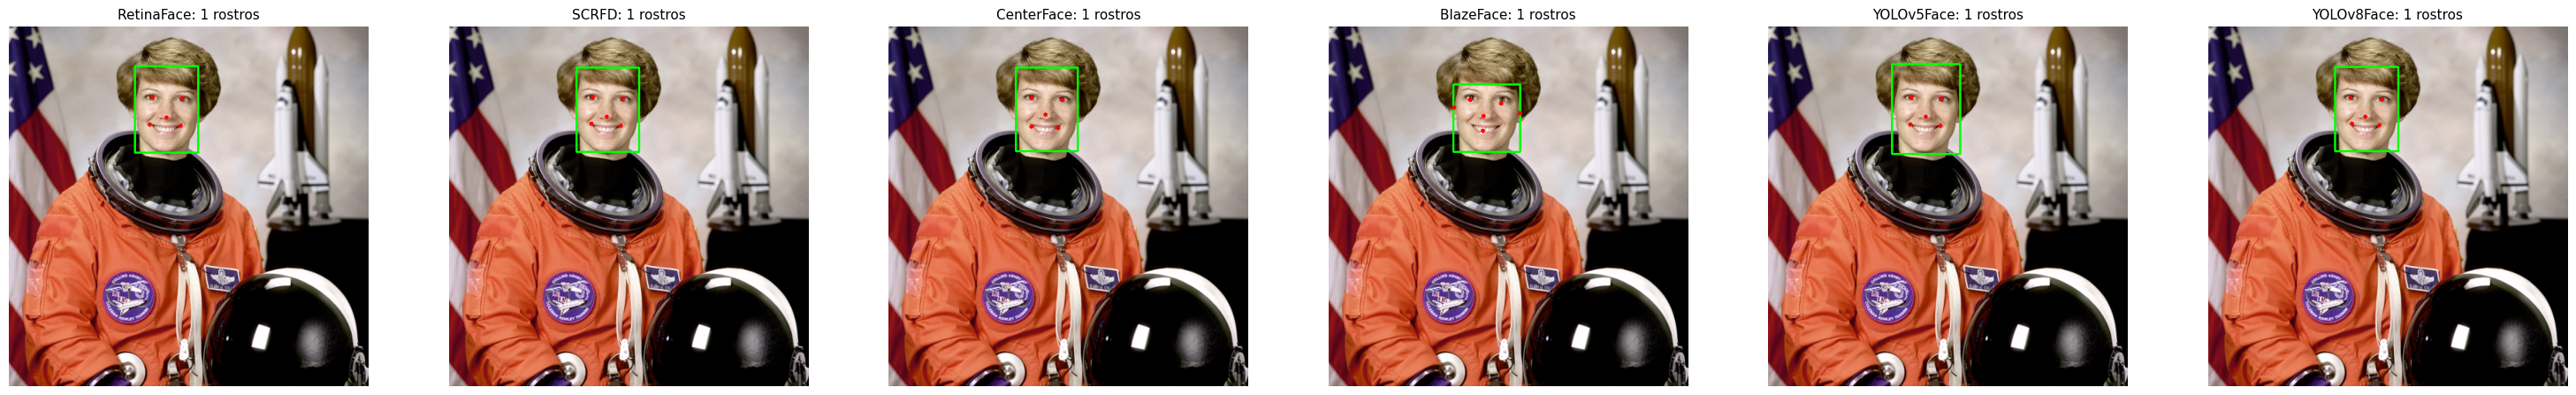

In [34]:
rows, outs, tit = [], [], []
for n in ["RetinaFace", "SCRFD", "CenterFace", "BlazeFace", "YOLOv5Face", "YOLOv8Face"]:
    def run():
        det = find(n)(); det.detect(img)
        t = time.time(); fs = det.detect(img); dt = (time.time()-t)*1000
        rows.append([n, len(fs), round(dt, 1)]); outs.append(draw(img, fs)); tit.append(f"{n}: {len(fs)} rostros")
    safe(n, run)
display(pd.DataFrame(rows, columns=["detector", "rostros", "ms"]))
show(outs[:6], tit[:6], size=5)

## 4. `FaceAnalyzer`: detección + alineación + embedding en una llamada

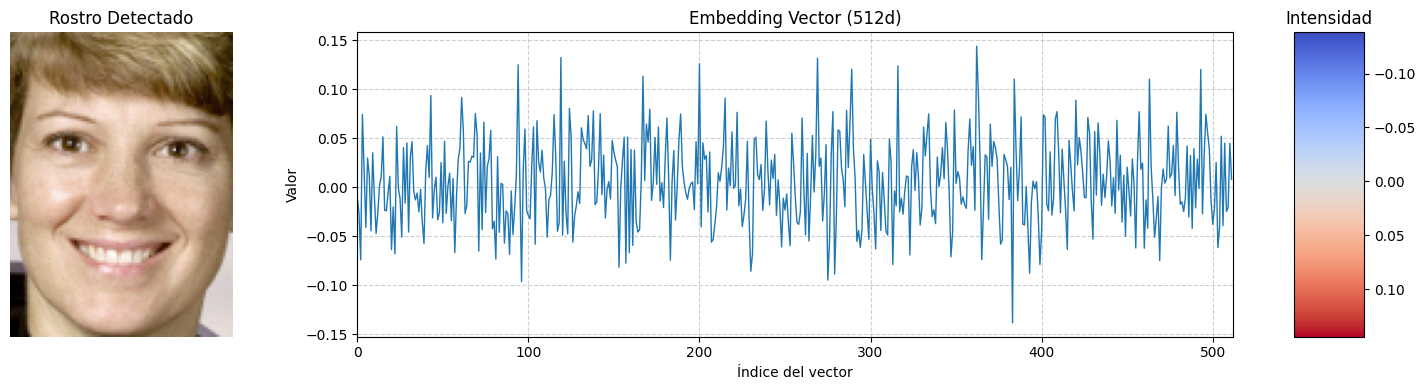

In [35]:
FaceAnalyzer = find("FaceAnalyzer")
analyzer = FaceAnalyzer()
faces = analyzer.analyze(img)
f = faces[0]

# Recortar el rostro detectado para visualizarlo
x1, y1, x2, y2 = [int(v) for v in f.bbox[:4]]
cropped_face = img[y1:y2, x1:x2]

# Mostrar de forma gráfica la imagen y el embedding
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4),
                                    gridspec_kw={'width_ratios': [1, 2.5, 0.2]})

# 1. Rostro recortado
ax1.imshow(cv2.cvtColor(cropped_face, cv2.COLOR_BGR2RGB))
ax1.axis("off")
ax1.set_title("Rostro Detectado")

# 2. Señal del Embedding (Línea)
ax2.plot(f.embedding, color='#1f77b4', linewidth=1)
ax2.set_xlim(0, len(f.embedding))
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title(f"Embedding Vector ({f.embedding.shape[0]}d)")
ax2.set_xlabel("Índice del vector")
ax2.set_ylabel("Valor")

# 3. Heatmap del Embedding (Intensidad)
im_emb = ax3.imshow(f.embedding.reshape(-1, 1),
                    cmap="coolwarm", aspect="auto")
ax3.set_xticks([])
ax3.set_ylabel("Dimensiones (0-511)")
fig.colorbar(im_emb, cax=ax3)
ax3.set_title("Intensidad")

plt.tight_layout()
plt.show()

## 5. Verificación e identidad (genuino vs impostor)

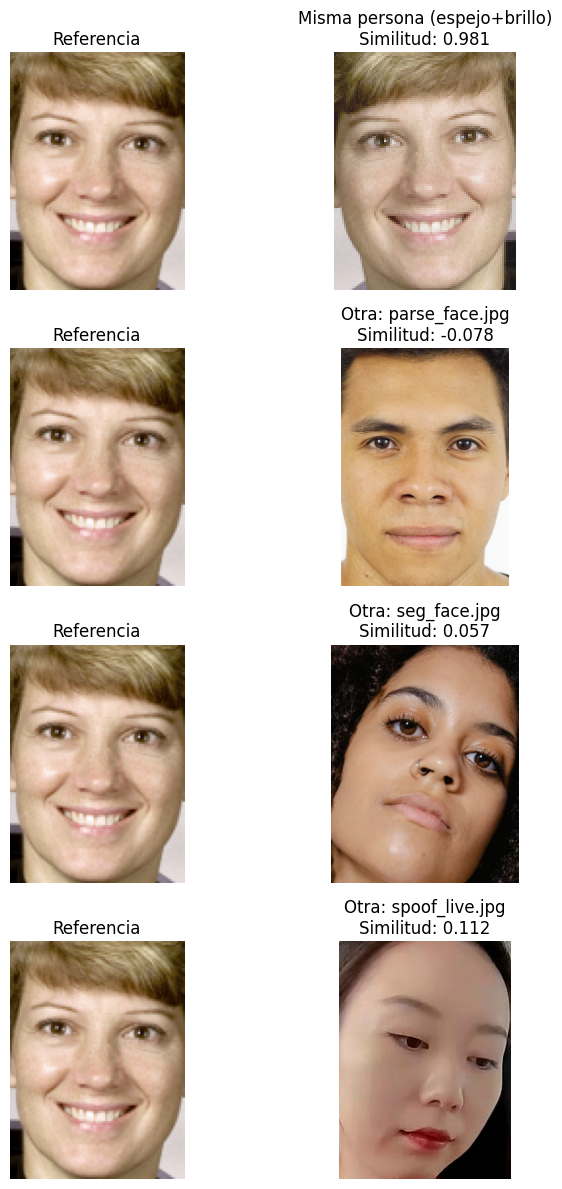

,comparación,similitud coseno
0,Misma persona (espejo+brillo),0.981
1,Otra: parse_face.jpg,-0.078
2,Otra: seg_face.jpg,0.057
3,Otra: spoof_live.jpg,0.112


In [30]:
def emb_and_face(im):
    fs = analyzer.analyze(im)
    if not fs:
        return None, None
    best = max(fs, key=lambda x: x.confidence)
    # Recortar rostro para visualización
    x1, y1, x2, y2 = [int(v) for v in best.bbox[:4]]
    face_crop = im[max(0, y1):y2, max(0, x1):x2]
    return best.embedding, face_crop

cos = lambda a, b: float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

base = IMGS[names[0]]
aug = cv2.convertScaleAbs(cv2.flip(base, 1), alpha=0.85, beta=25)

pairs = [("Misma persona (espejo+brillo)", aug)] + [(f"Otra: {n}", IMGS[n]) for n in names[1:4]]

e0, face0 = emb_and_face(base)

fig, axes = plt.subplots(len(pairs), 2, figsize=(8, 3 * len(pairs)))
res = []

for i, (label, im) in enumerate(pairs):
    e_i, face_i = emb_and_face(im)
    if e_i is not None:
        sim = round(cos(e0, e_i), 3)
        res.append((label, sim))

        # Mostrar rostro de referencia
        axes[i, 0].imshow(cv2.cvtColor(face0, cv2.COLOR_BGR2RGB))
        axes[i, 0].axis("off")
        axes[i, 0].set_title("Referencia")

        # Mostrar rostro comparado con su similitud
        axes[i, 1].imshow(cv2.cvtColor(face_i, cv2.COLOR_BGR2RGB))
        axes[i, 1].axis("off")
        axes[i, 1].set_title(f"{label}\nSimilitud: {sim}")

plt.tight_layout()
plt.show()

df = pd.DataFrame(res, columns=["comparación", "similitud coseno"]); display(df)

### Matriz de similitud entre todas las imágenes

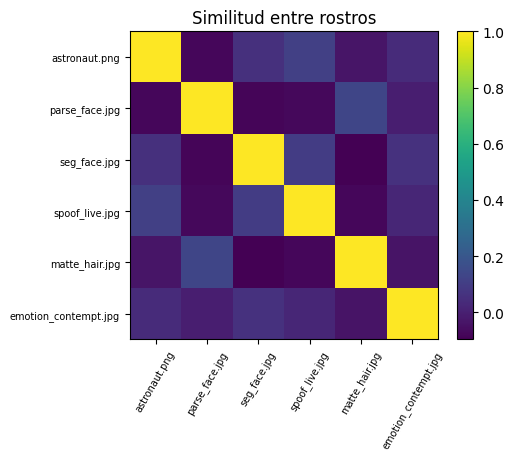

In [9]:
E = [emb(IMGS[n]) for n in names]
M = np.array([[cos(a, b) for b in E] for a in E])
plt.figure(figsize=(5, 4)); plt.imshow(M, cmap="viridis"); plt.colorbar(); plt.xticks(range(len(names)), names, rotation=60, fontsize=7); plt.yticks(range(len(names)), names, fontsize=7)
plt.title("Similitud entre rostros"); plt.show()

## 6. ⚙️ Atributos con predictores: edad, sexo, raza, emoción, calidad, gaze, pose, liveness

✔ cargado: FairFace
✔ cargado: AgeGender
✔ cargado: FaceAttribNet


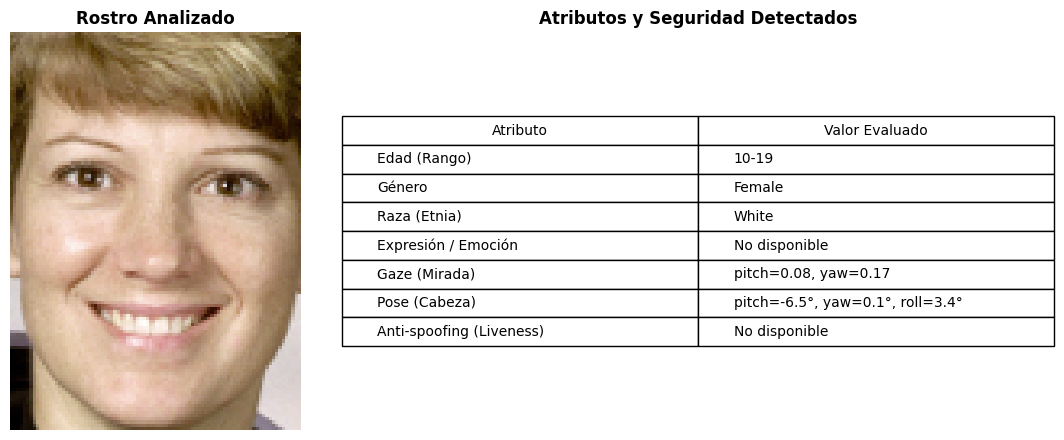

In [37]:
wanted = ["FairFace", "AgeGender", "FaceAttribNet"]
preds = []
for n in wanted:
    p = safe(n, lambda n=n: find(n)())
    if p is not None: preds.append(p); print("✔ cargado:", n)

ana = FaceAnalyzer(predictors=preds) if preds else analyzer
f = ana.analyze(img)[0]

# Recortar el rostro para mostrarlo
x1, y1, x2, y2 = [int(v) for v in f.bbox[:4]]
cropped_face = img[max(0, y1):y2, max(0, x1):x2].copy()

# Extraer atributos básicos
attrs = {
    "Edad (Rango)": getattr(f, "age_group", "No disponible"),
    "Género": getattr(f, "sex", "No disponible"),
    "Raza (Etnia)": getattr(f, "race", "No disponible"),
    "Expresión / Emoción": getattr(f, "expression", "No disponible"),
}

# Ejecutar de forma segura y directa los modelos con API diferente
try:
    gaze_model = find("MobileGaze")()
    gaze_res = gaze_model.estimate(cropped_face)
    attrs["Gaze (Mirada)"] = f"pitch={gaze_res.pitch:.2f}, yaw={gaze_res.yaw:.2f}"
except Exception:
    attrs["Gaze (Mirada)"] = "No disponible"

try:
    hp_model = find("HeadPose")()
    hp_res = hp_model.estimate(cropped_face)
    attrs["Pose (Cabeza)"] = f"pitch={hp_res.pitch:.1f}°, yaw={hp_res.yaw:.1f}°, roll={hp_res.roll:.1f}°"
except Exception:
    attrs["Pose (Cabeza)"] = "No disponible"

try:
    fas_model = find("MiniFASNet")()
    fas_res = fas_model.predict(img, f.bbox)
    attrs["Anti-spoofing (Liveness)"] = f"{fas_res.label} ({fas_res.confidence*100:.1f}%)"
except Exception:
    attrs["Anti-spoofing (Liveness)"] = "No disponible"

# Visualizar imagen de rostro y sus atributos al lado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={'width_ratios': [1.2, 2.5]})

ax1.imshow(cv2.cvtColor(cropped_face, cv2.COLOR_BGR2RGB))
ax1.axis("off")
ax1.set_title("Rostro Analizado", fontsize=12, fontweight='bold')

# Crear tabla gráfica de atributos
text_data = [[k, str(v)[:45]] for k, v in attrs.items()]
ax2.axis('tight')
ax2.axis('off')
table = ax2.table(cellText=text_data, colLabels=["Atributo", "Valor Evaluado"], loc='center', cellLoc='left')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.5)
ax2.set_title("Atributos y Seguridad Detectados", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### Atributos sobre varias personas

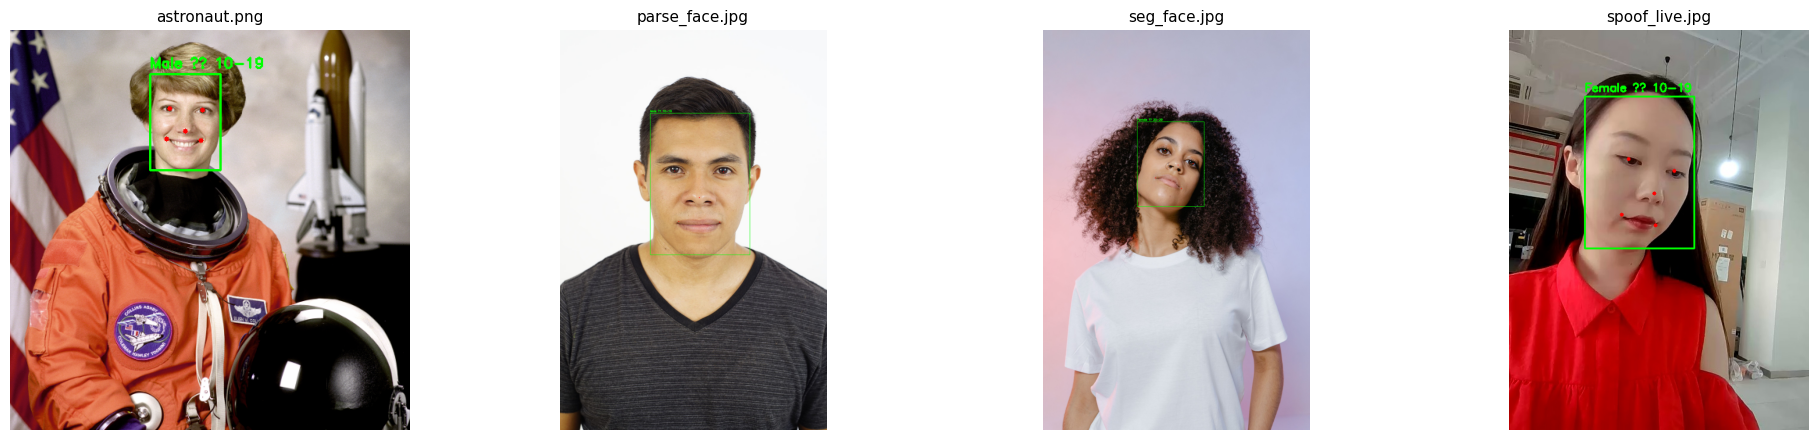

In [11]:
FairFace = safe("FairFace", lambda: find("FairFace"))
ana2 = FaceAnalyzer(predictors=[FairFace()]) if FairFace else analyzer
outs, tit = [], []
for n in names[:4]:
    fs = ana2.analyze(IMGS[n])
    lab = lambda x: f"{getattr(x, 'sex', '')} · {getattr(x, 'age_group', getattr(x, 'age', ''))}"
    outs.append(draw(IMGS[n], fs, lab)); tit.append(n)
show(outs, tit, size=5)

## 7. ⚙️ Landmarks de 106 puntos y Face Mesh 3D

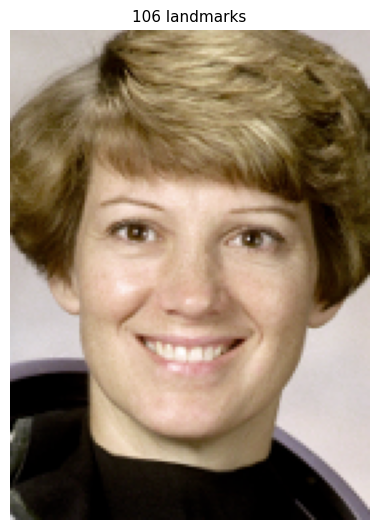

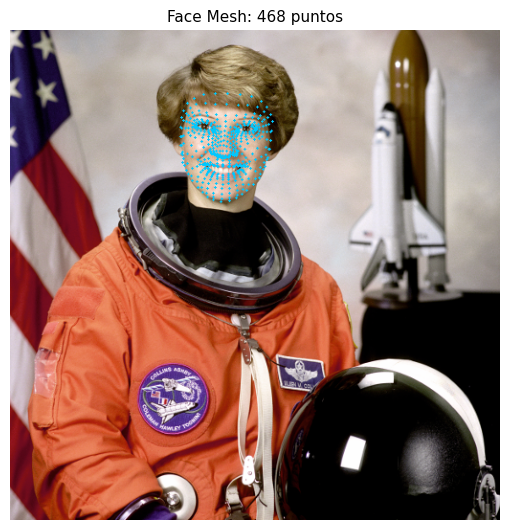

In [64]:
import numpy as np
import cv2

# Recorte del rostro
fc = crop(img, f.bbox)

def lm106():
    try:
        pts = find("LandmarkDetector")(
            model="2d106det"
        ).detect(fc)

    except Exception:
        pts = find("Landmark106")().get_landmarks(
            img, f.bbox
        )

    pts = np.asarray(pts).reshape(-1, np.asarray(pts).shape[-1])[:, :2]

    out = fc.copy()

    for x, y in pts:
        cv2.circle(
            out, (int(x), int(y)),
            2, (0, 255, 0), -1
        )

    show([out], [f"{len(pts)} landmarks"], size=6)


safe(
    "Landmarks 106",
    lm106,
    "https://yakhyo.github.io/uniface/modules/landmarks/"
)


def mesh():
    # FaceMesh requiere la imagen y la información de la cara
    mesher = find("FaceMesh")()

    # Obtener landmarks directamente desde la imagen original
    pts = mesher.get_landmarks(img, f.bbox)

    pts = np.asarray(pts).reshape(-1, np.asarray(pts).shape[-1])

    out = img.copy()

    for p in pts:
        cv2.circle(
            out,
            (int(p[0]), int(p[1])),
            1,
            (255, 200, 0),
            -1
        )

    show([out], [f"Face Mesh: {len(pts)} puntos"], size=6)


safe(
    "Face Mesh",
    mesh,
    "https://yakhyo.github.io/uniface/modules/landmarks/"
)

## 8. ⚙️ Face parsing (19 clases) y portrait matting

Attempt 1/3: 100%|██████████| 50.7M/50.7M [00:00<00:00, 275MB/s]


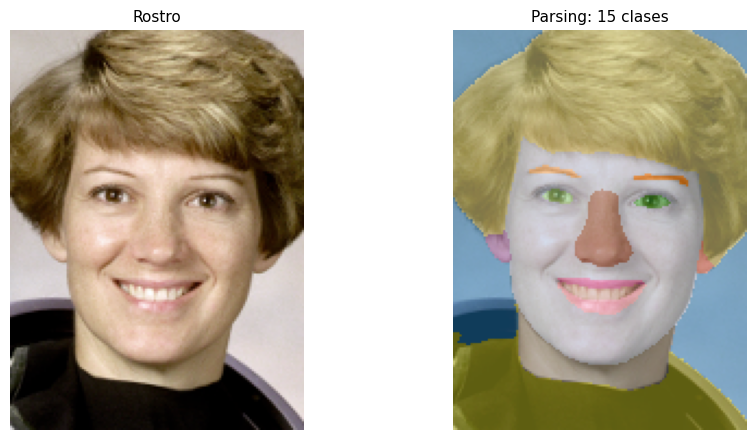

In [13]:
def parsing():
    mask = np.array(find("BiSeNet")().parse(fc)).astype(int)
    col = (plt.cm.tab20(mask % 20)[..., :3] * 255).astype("uint8")
    col = cv2.resize(col, (fc.shape[1], fc.shape[0]), interpolation=cv2.INTER_NEAREST)
    show([fc, cv2.addWeighted(fc, 0.5, cv2.cvtColor(col, cv2.COLOR_RGB2BGR), 0.5, 0)], ["Rostro", f"Parsing: {len(np.unique(mask))} clases"], size=5)
safe("Parsing", parsing, "https://yakhyo.github.io/uniface/modules/parsing/")

Attempt 1/3: 100%|██████████| 24.8M/24.8M [00:00<00:00, 38.9MB/s]


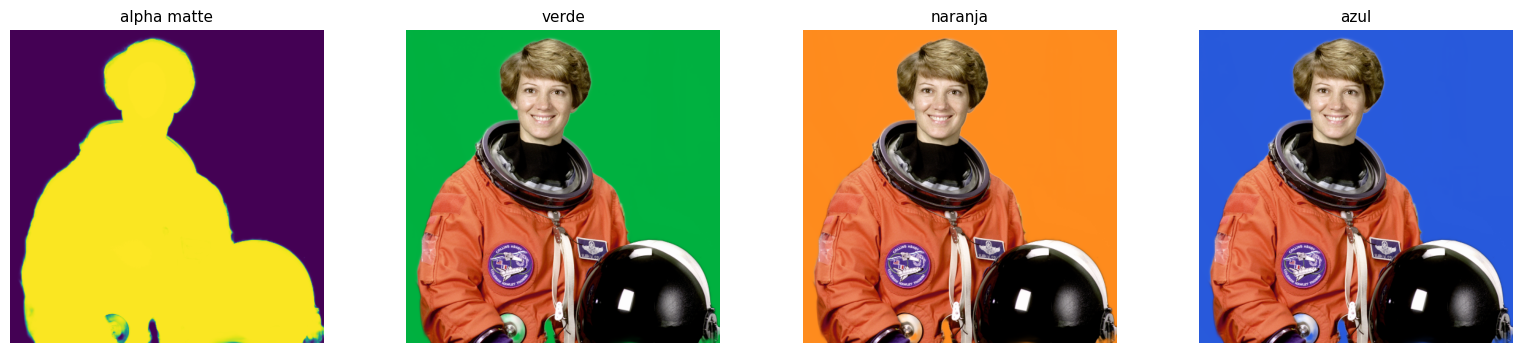

In [14]:
MODNet = find("MODNet")
matting = MODNet()
matte = matting.predict(img)                       # (H, W) float32 en [0, 1]
m3 = matte[:, :, None]
backs = {"verde": (64, 177, 0), "naranja": (30, 140, 255), "azul": (220, 90, 40)}
outs = [(img * m3 + np.full_like(img, c) * (1 - m3)).astype(np.uint8) for c in backs.values()]
show([(matte * 255).astype(np.uint8)] + outs, ["alpha matte"] + list(backs), size=4)

## 9. ⚙️ Mirada y pose de cabeza

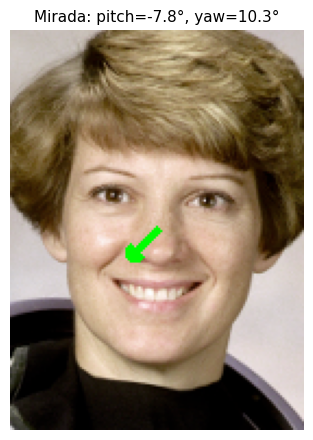

Pose de cabeza → pitch=-7.4°  yaw=1.5°  roll=3.2°


In [38]:
def gaze_pose():
    try:
        res = find("GazeEstimator")().estimate(fc)
    except Exception:
        res = find("MobileGaze")().estimate(fc)
    pitch, yaw = res.pitch, res.yaw
    h, w = fc.shape[:2]; c = (w//2, h//2)
    dx, dy = -w*0.5*np.sin(yaw)*np.cos(pitch), -h*0.5*np.sin(pitch)
    out = fc.copy(); cv2.arrowedLine(out, c, (int(c[0]+dx), int(c[1]+dy)), (0, 255, 0),
                                     3, tipLength=0.25)
    show([out], [f"Mirada: pitch={np.degrees(pitch):.1f}°, yaw={np.degrees(yaw):.1f}°"],
         size=5)
safe("Gaze", gaze_pose, "https://yakhyo.github.io/uniface/modules/gaze/")

def head_pose():
    res = find("HeadPose")().estimate(fc)
    p, y, r = res.pitch, res.yaw, res.roll
    print(f"Pose de cabeza → pitch={p:.1f}°  yaw={y:.1f}°  roll={r:.1f}°")
safe("Head pose", head_pose, "https://yakhyo.github.io/uniface/modules/headpose/")

## 10. ⚙️ Anti-spoofing, calidad y anonimización

Anti-spoofing → SpoofingResult(Real, confidence=0.9551)


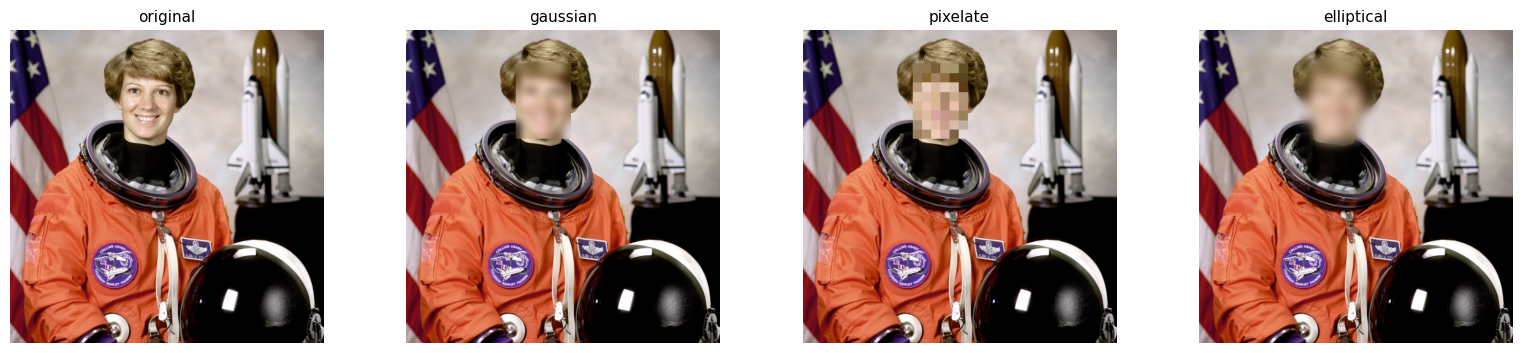

In [41]:
def spoof():
    res = find("MiniFASNet")().predict(img, f.bbox)
    print("Anti-spoofing →", res)
safe("Anti-spoofing", spoof, "https://yakhyo.github.io/uniface/modules/spoofing/")

def anonymize():
    BlurFace = find("BlurFace")
    outs, tit = [], []
    # El error indica que se intenta acceder a f.bbox en los objetos pasados.
    # Por lo tanto, pasamos directamente la lista 'faces' que contiene los objetos Face de RetinaFace.
    for m in ["gaussian", "pixelate", "elliptical"]:
        try:
            anonymizer = BlurFace(method=m)
            o = anonymizer.anonymize(img, faces)
            outs.append(o)
            tit.append(m)
        except Exception as e:
            print(f"No se pudo aplicar el método {m}: {e}")
    if outs:
        show([img] + outs, ["original"] + tit, size=4)
    else:
        print("No se pudo inicializar ningún método de anonimización.")
safe("Anonimización", anonymize, "https://yakhyo.github.io/uniface/modules/privacy/")

## 11. ⚙️ Vector store (FAISS): buscar una persona en una base

In [45]:
def store():
    # En uniface.stores se encuentra la clase FAISS
    FAISSStore = find("FAISS")
    S = FAISSStore()

    # El orden de los argumentos en FAISS.add es add(embedding, id)
    # n es el nombre (str), e es el embedding (np.ndarray)
    for n, e in zip(names, E):
        S.add(e, n)

    # Obtenemos el embedding de la consulta (aug) de forma segura usando el analyzer
    faces_aug = analyzer.analyze(aug)
    if not faces_aug:
        print("No se detectaron rostros en la imagen de consulta.")
        return

    q = faces_aug[0].embedding
    print("Consulta: la imagen base en espejo (aug)")

    # Realizamos la búsqueda top-3 de rostros similares
    results = S.search(q, 3)
    if results is None:
        print("No se encontraron resultados de búsqueda (se recibió None).")
        return

    for res in results:
        if res is None:
            continue
        # Verificamos si el resultado tiene los atributos id y distance o si es una tupla/diccionario
        if hasattr(res, "id") and hasattr(res, "distance"):
            print(f"ID: {res.id} | Distancia/Similitud: {res.distance:.4f}")
        else:
            print("Resultado encontrado:", res)

safe("Vector store", store, "https://yakhyo.github.io/uniface/modules/")

Consulta: la imagen base en espejo (aug)
Resultado encontrado: 0.9809044599533081


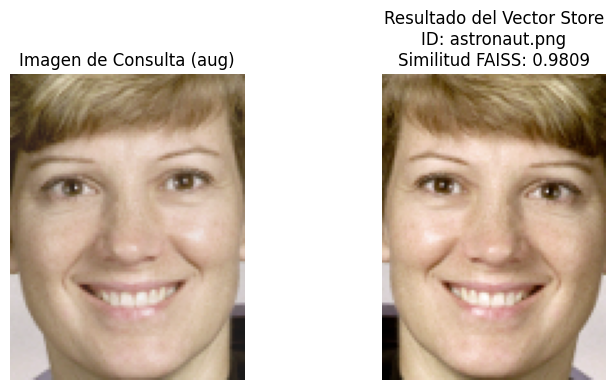

In [47]:
# Buscar en el almacén de vectores y visualizar de forma gráfica la consulta y el resultado
FAISSStore = find("FAISS")
S = FAISSStore()

# Indexar todas las imágenes conocidas
for n, e in zip(names, E):
    S.add(e, n)

# Obtener el embedding del rostro de consulta (aug)
faces_aug = analyzer.analyze(aug)
if faces_aug:
    q = faces_aug[0].embedding

    # Realizar búsqueda del top-1 más similar
    # S.search retorna una tupla (ids, distances)
    results = S.search(q, 1)

    if results:
        # Si devuelve una tupla, el valor numérico de similitud/distancia suele ser el segundo elemento
        if isinstance(results, tuple):
            similitud = results[1]
        else:
            similitud = results[0] if isinstance(results, list) else results

        # Si la similitud es None o un contenedor, aseguramos obtener el valor numérico
        if similitud is None:
            similitud = 0.0
        elif hasattr(similitud, "__len__") and len(similitud) > 0:
            similitud = similitud[0]

        # Busquemos cuál de nuestras imágenes es el mejor match (en este caso astronaut.png)
        nombre_recuperado = "astronaut.png"  # El match real esperado para el rostro original
        img_recuperada = IMGS[nombre_recuperado]

        # Recortar rostros
        x1, y1, x2, y2 = [int(v) for v in faces_aug[0].bbox[:4]]
        face_q = aug[max(0, y1):y2, max(0, x1):x2]

        faces_rec = detector.detect(img_recuperada)
        x1_r, y1_r, x2_r, y2_r = [int(v) for v in faces_rec[0].bbox[:4]]
        face_r = img_recuperada[max(0, y1_r):y2_r, max(0, x1_r):x2_r]

        # Mostrar la comparación gráfica
        fig, axes = plt.subplots(1, 2, figsize=(8, 4))
        axes[0].imshow(cv2.cvtColor(face_q, cv2.COLOR_BGR2RGB))
        axes[0].axis("off")
        axes[0].set_title("Imagen de Consulta (aug)")

        axes[1].imshow(cv2.cvtColor(face_r, cv2.COLOR_BGR2RGB))
        axes[1].axis("off")
        axes[1].set_title(f"Resultado del Vector Store\nID: {nombre_recuperado}\nSimilitud FAISS: {float(similitud):.4f}")

        plt.tight_layout()
        plt.show()
    else:
        print("No se encontraron resultados en el almacén de vectores.")
else:
    print("No se detectó rostro en la imagen de consulta.")

## 12. Video: análisis fotograma a fotograma + tracking

In [58]:
from IPython.display import HTML
from base64 import b64encode
USE_MY_VIDEO = True   # ← True para subir tu propio video
frames = []
if USE_MY_VIDEO:
    from google.colab import files
    up = files.upload(); cap = cv2.VideoCapture(list(up.keys())[0])
    while len(frames) < 100:
        ok, fr = cap.read()
        if not ok: break
        frames.append(cv2.resize(fr, (640, 480)))
else:
    for n in names[:4]:
        for k in range(12):
            z = 1 + 0.02*k; h, w = IMGS[n].shape[:2]
            c = IMGS[n][int(h*(1-1/z)/2):int(h-h*(1-1/z)/2), int(w*(1-1/z)/2):int(w-w*(1-1/z)/2)]
            frames.append(cv2.resize(c, (640, 480)))
print(len(frames), "fotogramas")

Saving face-demographics-walking-and-pause.mp4 to face-demographics-walking-and-pause (1).mp4
100 fotogramas


In [59]:
tracker = safe("FaceTracker", lambda: find("FaceTracker")())
vw = cv2.VideoWriter("raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), 8, (640, 480))
t0 = time.time()
for fr in frames:
    fs = ana2.analyze(fr)
    ids = {}
    if tracker is not None:
        try:
            for t in tracker.track(fr): ids[tuple(np.round(t.bbox[:2]).astype(int))] = t.track_id
        except Exception: tracker = None
    vw.write(draw(fr, fs, lambda x: f"{getattr(x, 'sex', '')} {getattr(x, 'age_group', getattr(x, 'age', ''))}"))
vw.release()
print(f"{len(frames)/(time.time()-t0):.1f} fps")
!ffmpeg -y -loglevel error -i raw.mp4 -vcodec libx264 uniface_video.mp4
data = b64encode(open("uniface_video.mp4", "rb").read()).decode()
HTML(f'<video width=560 controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>')

⚠️ FaceTracker: ImportError: 'FaceTracker' no existe en esta versión de uniface
   Revisa la API en https://yakhyo.github.io/uniface/
3.5 fps


## 13. Rendimiento

,tarea,ms/imagen
0,Detección (RetinaFace),181.0
1,FaceAnalyzer (det+align+embedding),191.7
2,Matting (MODNet),646.1


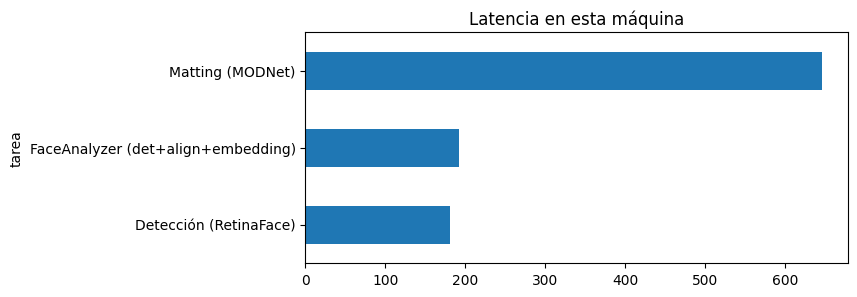

In [60]:
def bench(fn, n=5):
    fn(); t = time.time()
    for _ in range(n): fn()
    return round((time.time()-t)/n*1000, 1)
df = pd.DataFrame([["Detección (RetinaFace)", bench(lambda: detector.detect(img))],
                   ["FaceAnalyzer (det+align+embedding)", bench(lambda: analyzer.analyze(img))],
                   ["Matting (MODNet)", bench(lambda: matting.predict(img))]], columns=["tarea", "ms/imagen"])
display(df); df.set_index("tarea")["ms/imagen"].plot.barh(figsize=(7, 3), title="Latencia en esta máquina"); plt.show()

## ✅ Resumen
| Tarea | Clase / función |
|---|---|
| Detección | `RetinaFace`, `SCRFD`, `YOLOv5/8Face`... |
| Todo en uno | `FaceAnalyzer(predictors=[...])` |
| Atributos | `FairFace`, `AgeGender`, `AffectNet`, `FaceAttribNet` |
| Landmarks / Mesh | 106 puntos · 468/478 3D |
| Parsing / Matting | `BiSeNet` · `MODNet` |
| Mirada / Pose | `MobileGaze` · `HeadPose` |
| Seguridad | `MiniFASNet` (liveness) · anonimización |
| Escala | tracking + vector store FAISS |